# El Valle de Aburrá envejece: ¿qué pasará con su población hasta 2050?

Análisis de las proyecciones oficiales de población del **DANE** (PPED, actualización del 30 de julio de 2025) para la región demográfica **Valle de Aburrá**, con Python y MySQL.

**Pregunta:** ¿cómo cambiará la estructura por edad y sexo del Valle de Aburrá hasta 2050, y qué implica para la población en edad de trabajar?

**Contenido**
1. Configuración
2. Carga y transformación del archivo del DANE
3. Validación
4. Indicadores demográficos
5. Carga a MySQL
6. Análisis con SQL
7. Visualizaciones
8. Conclusiones y exportación para el dashboard

## 1. Configuración

In [1]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Lee las credenciales del archivo .env (que NO se sube a GitHub; ver .env.example)
load_dotenv()

# Archivo del DANE: descárgalo y guárdalo en data/raw/
RUTA_XLSX = Path("data/raw/PPED-AreaSexoEdadReg-2018-2050.xlsx")
HOJA = "PobRegionalxÁreaSexoEdad"
SIGLA_REGION = "VDA"  # Valle de Aburrá

# Conexión a MySQL
MYSQL = {
    "host": os.getenv("MYSQL_HOST", "127.0.0.1"),
    "port": int(os.getenv("MYSQL_PORT", "3306")),
    "user": os.getenv("MYSQL_USER", "root"),
    "password": os.getenv("MYSQL_PASSWORD"),
}
if not MYSQL["password"]:
    raise ValueError("Falta MYSQL_PASSWORD: créala en tu archivo .env (ver .env.example)")

BASE_DATOS = "vda_envejecimiento"

Path("data").mkdir(exist_ok=True)
Path("dashboard/img").mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

## 2. Carga y transformación

El archivo trae una fila por región, año y área, con **310 columnas**: totales, y luego población por edad simple (0 a 100+) para hombres, mujeres y ambos sexos. Lo convertimos a **formato largo**: una fila por año, área, sexo y edad.

In [2]:
raw = pd.read_excel(RUTA_XLSX, sheet_name=HOJA, header=None)

# Estructura de columnas (índice base 0):
#   0 sigla · 1 territorio · 2 año · 3 área · 4 total · 5 hombres · 6 mujeres
#   7..107 hombres 0..100+ · 108..208 mujeres 0..100+ · 209..309 total ambos sexos
raw = raw[raw[0] == SIGLA_REGION].copy()
raw[2] = raw[2].astype(int)

print("Región:", raw[1].iloc[0])
print("Años:", raw[2].min(), "-", raw[2].max())
print("Filas (año x área):", len(raw))

Región: Valle de Aburrá
Años: 2018 - 2050
Filas (año x área): 89


In [4]:
EDADES = list(range(101))  # 100 = "100 años y más"

def a_formato_largo(raw: pd.DataFrame) -> pd.DataFrame:
    piezas = []
    for sexo, inicio in (("Hombres", 7), ("Mujeres", 108)):
        cols = [2, 3] + [inicio + e for e in EDADES]
        sub = raw[cols].copy()
        sub.columns = ["anio", "area"] + EDADES
        largo = sub.melt(id_vars=["anio", "area"], var_name="edad", value_name="poblacion")
        largo["sexo"] = sexo
        piezas.append(largo)

    df = pd.concat(piezas, ignore_index=True)
    df["area"] = df["area"].replace({"Centros Poblados y Rural Disperso": "Rural"})
    df[["edad", "poblacion"]] = df[["edad", "poblacion"]].astype(int)
    return (df[["anio", "area", "sexo", "edad", "poblacion"]]
            .sort_values(["anio", "area", "sexo", "edad"])
            .reset_index(drop=True))

largo = a_formato_largo(raw)
print(f"{len(largo):,} filas")
largo.head()

17,978 filas


,anio,area,sexo,edad,poblacion
0,2018,Cabecera,Hombres,0,20308
1,2018,Cabecera,Hombres,1,20945
2,2018,Cabecera,Hombres,2,21480
3,2018,Cabecera,Hombres,3,22043
4,2018,Cabecera,Hombres,4,22503


## 3. Validación

Antes de analizar, comprobamos que al sumar las edades obtenemos exactamente el total oficial del DANE.

In [5]:
esperado = raw.assign(area=raw[3].replace({"Centros Poblados y Rural Disperso": "Rural"})) \
              .set_index([2, "area"])[4]
obtenido = largo.groupby(["anio", "area"])["poblacion"].sum()

diferencia = (esperado.values - obtenido.reindex(esperado.index).values)
assert (diferencia == 0).all(), "Descuadre con los totales del DANE"
assert (largo["poblacion"] >= 0).all(), "Hay poblaciones negativas"
assert largo.duplicated(["anio", "area", "sexo", "edad"]).sum() == 0, "Hay filas duplicadas"

print(f"Validación OK: {len(esperado)} combinaciones año/área cuadran con el total del DANE")
print(largo.groupby("area")["anio"].agg(["min", "max"]))

Validación OK: 89 combinaciones año/área cuadran con el total del DANE
           min   max
area                
Cabecera  2018  2045
Rural     2018  2045
Total     2018  2050


> **Nota sobre cobertura:** el desglose por **Cabecera** y **Rural** llega solo hasta **2045**; el **Total** llega hasta **2050**.

## 4. Indicadores demográficos

- **Índice de envejecimiento:** mayores de 65 por cada 100 menores de 15.
- **Razón de dependencia total:** (menores de 15 + mayores de 65) por cada 100 personas de 15 a 64.
- **Edad mediana:** edad que divide a la población en dos mitades iguales (interpolada).
- **Razón de feminidad en 65+:** mujeres por cada 100 hombres.

In [6]:
def edad_mediana(pob: np.ndarray) -> float:
    acum = pob.cumsum()
    mitad = acum[-1] / 2
    i = int(np.searchsorted(acum, mitad))
    previo = acum[i - 1] if i > 0 else 0
    return round(float(i + (mitad - previo) / pob[i]), 1)

def calcular_indicadores(largo: pd.DataFrame) -> pd.DataFrame:
    filas = []
    for (anio, area), g in largo.groupby(["anio", "area"]):
        pob = g.groupby("edad")["poblacion"].sum().reindex(EDADES).values
        total, p0_14, p15_64 = pob.sum(), pob[:15].sum(), pob[15:65].sum()
        p65, p80 = pob[65:].sum(), pob[80:].sum()
        h = g[g.sexo == "Hombres"].set_index("edad")["poblacion"]
        m = g[g.sexo == "Mujeres"].set_index("edad")["poblacion"]
        filas.append({
            "anio": anio, "area": area,
            "poblacion_total": int(total), "pob_0_14": int(p0_14), "pob_15_64": int(p15_64),
            "pob_65_mas": int(p65), "pob_80_mas": int(p80),
            "pct_0_14": round(p0_14 / total * 100, 2), "pct_15_64": round(p15_64 / total * 100, 2),
            "pct_65_mas": round(p65 / total * 100, 2), "pct_80_mas": round(p80 / total * 100, 2),
            "indice_envejecimiento": round(p65 / p0_14 * 100, 1),
            "razon_dependencia": round((p0_14 + p65) / p15_64 * 100, 1),
            "razon_dep_vejez": round(p65 / p15_64 * 100, 1),
            "edad_mediana": edad_mediana(pob),
            "mujeres_por_100_hombres_65_mas": round(m.loc[65:].sum() / h.loc[65:].sum() * 100, 1),
        })
    return pd.DataFrame(filas).sort_values(["area", "anio"]).reset_index(drop=True)

indicadores = calcular_indicadores(largo)
indicadores.query("area == 'Total' and anio in [2018, 2025, 2035, 2050]").set_index("anio").T

anio,2018,2025,2035,2050
area,Total,Total,Total,Total
poblacion_total,3870058,4194012,4304040,4162895
pob_0_14,740706,700671,578152,409820
pob_15_64,2721562,2971436,2991323,2767906
pob_65_mas,407790,521905,734565,985169
pob_80_mas,93314,103563,166869,312965
pct_0_14,19.14,16.71,13.43,9.84
pct_15_64,70.32,70.85,69.5,66.49
pct_65_mas,10.54,12.44,17.07,23.67
pct_80_mas,2.41,2.47,3.88,7.52


## 5. Carga a MySQL

Se crea la base `vda_envejecimiento` con el esquema de `01_esquema_mysql.sql` y se cargan las dos tablas: `poblacion` e `indicadores`.

In [10]:
# Conexión a nivel de servidor para crear la base
url_servidor = URL.create("mysql+pymysql", username=MYSQL["user"], password=MYSQL["password"],
                          host=MYSQL["host"], port=MYSQL["port"])
engine_servidor = create_engine(url_servidor)

esquema = Path("01_esquema_mysql.sql").read_text(encoding="utf-8")
sentencias = [s.strip() for s in esquema.split(";")]
sentencias = [s for s in sentencias if re.sub(r"--.*", "", s).strip()]

with engine_servidor.begin() as con:
    for s in sentencias:
        con.execute(text(s))
print(f"Esquema creado ({len(sentencias)} sentencias)")

# Conexión a la base ya creada
engine = create_engine(URL.create("mysql+pymysql", username=MYSQL["user"], password=MYSQL["password"],
                                  host=MYSQL["host"], port=MYSQL["port"], database=BASE_DATOS))

Esquema creado (6 sentencias)


In [11]:
largo.to_sql("poblacion", engine, if_exists="append", index=False, method="multi", chunksize=2000)
indicadores.to_sql("indicadores", engine, if_exists="append", index=False, method="multi", chunksize=500)

with engine.connect() as con:
    for tabla in ("poblacion", "indicadores"):
        n = con.execute(text(f"SELECT COUNT(*) FROM {tabla}")).scalar()
        print(f"{tabla:12s} {n:>7,} filas")
    print("Versión del servidor:", con.execute(text("SELECT VERSION()")).scalar())

poblacion     17,978 filas
indicadores       89 filas
Versión del servidor: 8.4.10


## 6. Análisis con SQL

Las consultas viven en `03_consultas_mysql.sql` (CTEs, `LAG`, `RANK`, pivotes con `CASE`). La función `consulta(n)` ejecuta la consulta *n* y devuelve un DataFrame.

In [12]:
sql_consultas = Path("03_consultas_mysql.sql").read_text(encoding="utf-8")
CONSULTAS = {int(n): bloque.strip().rstrip(";")
             for bloque, n in re.findall(r"(?ms)^(-- Q(\d+)\..*?)(?=^-- Q\d+\.|\Z)", sql_consultas)}

def consulta(n: int) -> pd.DataFrame:
    with engine.connect() as con:
        return pd.read_sql(text(CONSULTAS[n]), con)

print("Consultas disponibles:", sorted(CONSULTAS))

Consultas disponibles: [1, 2, 3, 4, 5, 6, 7, 8]


### Q1 · Edad mediana y peso de los mayores de 65

In [13]:
consulta(1)

,anio,poblacion_total,pct_65_mas,edad_mediana,cambio_edad_mediana_5a,cambio_pct_65_5a
0,2018,3870058,10.54,33.1,NaN,NaN
1,2023,4136142,11.65,34.8,1.7,1.11
2,2028,4242926,13.86,37.2,2.4,2.21
3,2033,4294062,16.25,39.9,2.7,2.39
4,2038,4306551,18.09,42.7,2.8,1.84
5,2043,4276002,19.86,45.5,2.8,1.77
6,2048,4203025,22.49,48.2,2.7,2.63
7,2050,4162895,23.67,49.2,2.6,2.83


### Q2 · ¿Cuándo hay más adultos mayores que menores de 15 años?

In [14]:
consulta(2)

,anio_inversion,mayores_65,menores_15,indice_envejecimiento
0,2031,656203,627091,104.6


### Q3 · ¿Cuándo deja de crecer la población?

In [15]:
q3 = consulta(3)
q3

,anio,poblacion_total,variacion_anual,crecimiento_pct,nota
0,2030,4267609,11675,0.27,
1,2031,4277885,10276,0.24,
2,2032,4286720,8835,0.21,
3,2033,4294062,7342,0.17,
4,2034,4299853,5791,0.13,
5,2035,4304040,4187,0.10,
6,2036,4306578,2538,0.06,
7,2037,4307425,847,0.02,PICO
8,2038,4306551,-874,-0.02,
9,2039,4303936,-2615,-0.06,


### Q4 · Razón de dependencia

In [16]:
consulta(4)

,anio,dependencia_jovenes,dependencia_vejez,dependencia_total
0,2018,27.2,15.0,42.2
1,2025,23.6,17.6,41.1
2,2030,21.4,21.2,42.5
3,2035,19.3,24.6,43.9
4,2040,17.4,27.1,44.5
5,2045,15.9,30.5,46.4
6,2050,14.8,35.6,50.4


### Q5 · Pirámide por grupos quinquenales: 2025 frente a 2050

In [17]:
q5 = consulta(5)
q5

,grupo_edad,hombres_2025,mujeres_2025,hombres_2050,mujeres_2050
0,0-4,107332.0,101901.0,62300.0,59025.0
1,5-9,119687.0,113688.0,69816.0,65866.0
2,10-14,131925.0,126138.0,78663.0,74150.0
3,15-19,143213.0,138443.0,89479.0,84523.0
4,20-24,155547.0,152798.0,101541.0,95928.0
5,25-29,184307.0,184717.0,113905.0,107545.0
6,30-34,195586.0,191600.0,126977.0,120119.0
7,35-39,172999.0,172584.0,139984.0,133158.0
8,40-44,149603.0,158079.0,150833.0,144847.0
9,45-49,123412.0,141975.0,159181.0,156415.0


### Q6 · ¿Qué grupos de edad ganan y pierden más gente?

In [18]:
consulta(6)

,grupo_edad,pob_2025,pob_2050,cambio_absoluto,cambio_pct,ranking_ganancia
0,80+,103563.0,312965.0,209402.0,202.2,1
1,50-54,232671.0,359315.0,126644.0,54.4,2
2,55-59,243118.0,365270.0,122152.0,50.2,3
3,65-69,185632.0,275012.0,89380.0,48.1,4
4,60-64,230784.0,318886.0,88102.0,38.2,5
5,70-74,138625.0,222997.0,84372.0,60.9,6
6,75-79,94085.0,174195.0,80110.0,85.1,7
7,45-49,265387.0,315596.0,50209.0,18.9,8
8,40-44,307682.0,295680.0,-12002.0,-3.9,9
9,35-39,345583.0,273142.0,-72441.0,-21.0,10


### Q7 · Feminización de la vejez

In [19]:
consulta(7)

,anio,grupo,mujeres_por_100_hombres
0,2018,65-79,143.2
1,2030,65-79,146.1
2,2050,65-79,125.4
3,2018,80+,174.1
4,2030,80+,182.6
5,2050,80+,168.4


### Q8 · Cabecera y rural (hasta 2045)

In [20]:
consulta(8)

,anio,pct_65_cabecera,pct_65_rural,edad_mediana_cabecera,edad_mediana_rural,poblacion_rural
0,2018,10.64,8.83,33.2,31.4,220938
1,2025,12.56,10.52,35.8,34.3,238202
2,2035,17.22,14.52,41.1,39.8,243261
3,2045,21.02,17.78,46.7,44.9,239342


## 7. Visualizaciones

In [21]:
with engine.connect() as con:
    total = pd.read_sql(text("SELECT * FROM indicadores WHERE area = 'Total' ORDER BY anio"), con)

anio_pico = int(total.loc[total.poblacion_total.idxmax(), "anio"])
anio_inversion = int(consulta(2).loc[0, "anio_inversion"])
print("Año pico de población:", anio_pico, "· Año de inversión (65+ > 0-14):", anio_inversion)

Año pico de población: 2037 · Año de inversión (65+ > 0-14): 2031


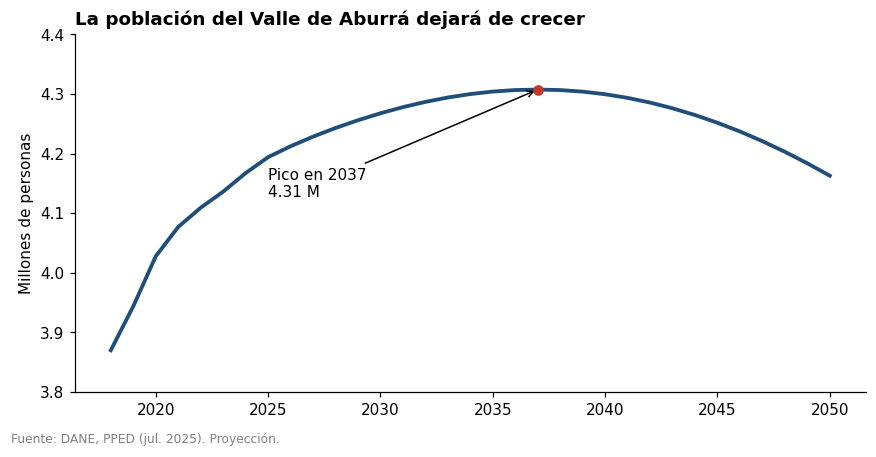

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(total.anio, total.poblacion_total / 1e6, color="#1f4e79", lw=2.5)
pico = total.loc[total.anio == anio_pico].iloc[0]
ax.scatter(anio_pico, pico.poblacion_total / 1e6, color="#c0392b", zorder=5)
ax.annotate(f"Pico en {anio_pico}\n{pico.poblacion_total/1e6:.2f} M", (anio_pico, pico.poblacion_total / 1e6),
            xytext=(anio_pico - 12, pico.poblacion_total / 1e6 - 0.18), arrowprops=dict(arrowstyle="->"))
ax.set_title("La población del Valle de Aburrá dejará de crecer", loc="left", fontweight="bold")
ax.set_ylabel("Millones de personas")
ax.set_ylim(3.8, 4.4)
fig.text(0.01, -0.02, "Fuente: DANE, PPED (jul. 2025). Proyección.", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig("dashboard/img/01_poblacion_total.png", bbox_inches="tight")
plt.show()

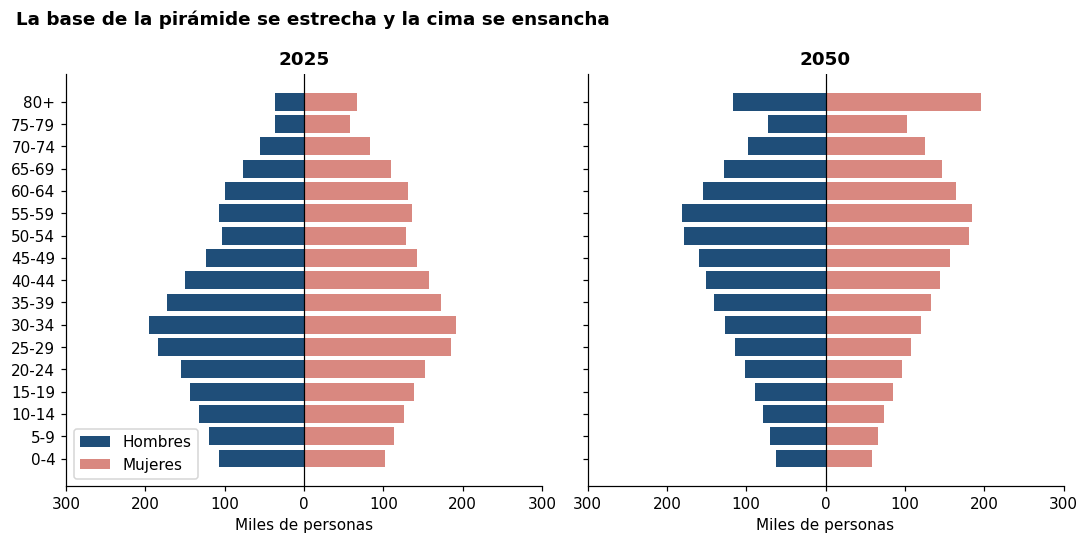

In [23]:
orden = q5["grupo_edad"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True, sharex=True)
for ax, anio in zip(axes, (2025, 2050)):
    ax.barh(orden, -q5[f"hombres_{anio}"] / 1e3, color="#1f4e79", label="Hombres")
    ax.barh(orden, q5[f"mujeres_{anio}"] / 1e3, color="#d98880", label="Mujeres")
    ax.set_title(str(anio), fontweight="bold")
    ax.set_xlabel("Miles de personas")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xticks([-300, -200, -100, 0, 100, 200, 300])
    ax.set_xticklabels([300, 200, 100, 0, 100, 200, 300])
axes[0].legend(loc="lower left")
fig.suptitle("La base de la pirámide se estrecha y la cima se ensancha", fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
fig.savefig("dashboard/img/02_piramide_2025_2050.png", bbox_inches="tight")
plt.show()

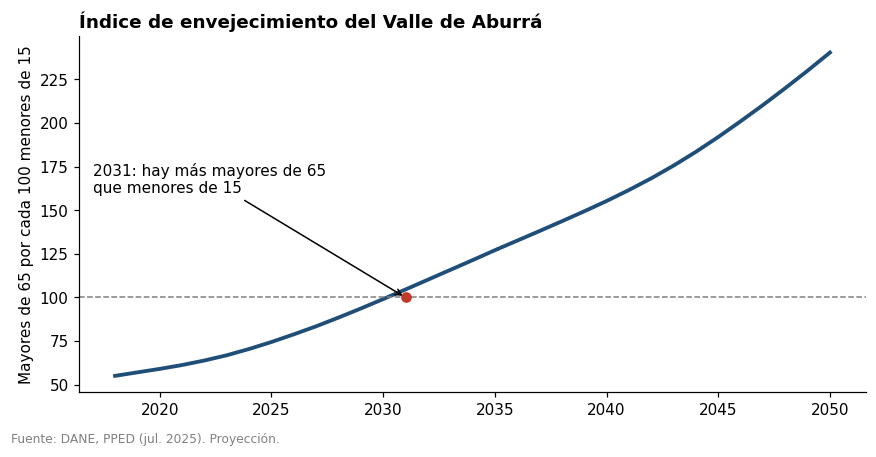

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(total.anio, total.indice_envejecimiento, color="#1f4e79", lw=2.5)
ax.axhline(100, color="gray", ls="--", lw=1)
ax.scatter(anio_inversion, 100, color="#c0392b", zorder=5)
ax.annotate(f"{anio_inversion}: hay más mayores de 65\nque menores de 15", (anio_inversion, 100),
            xytext=(anio_inversion - 14, 160), arrowprops=dict(arrowstyle="->"))
ax.set_title("Índice de envejecimiento del Valle de Aburrá", loc="left", fontweight="bold")
ax.set_ylabel("Mayores de 65 por cada 100 menores de 15")
fig.text(0.01, -0.02, "Fuente: DANE, PPED (jul. 2025). Proyección.", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig("dashboard/img/03_indice_envejecimiento.png", bbox_inches="tight")
plt.show()

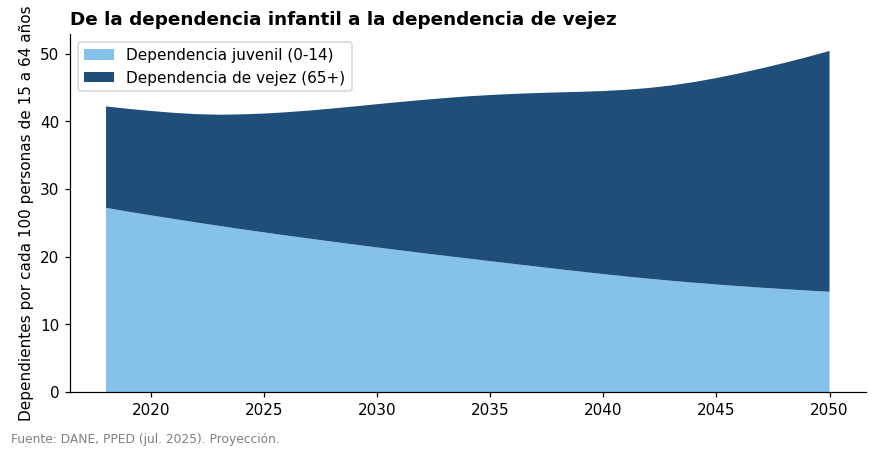

In [25]:
dep_jov = 100 * total.pob_0_14 / total.pob_15_64
dep_vej = 100 * total.pob_65_mas / total.pob_15_64

fig, ax = plt.subplots(figsize=(8, 4))
ax.stackplot(total.anio, dep_jov, dep_vej, colors=["#85c1e9", "#1f4e79"],
             labels=["Dependencia juvenil (0-14)", "Dependencia de vejez (65+)"])
ax.set_title("De la dependencia infantil a la dependencia de vejez", loc="left", fontweight="bold")
ax.set_ylabel("Dependientes por cada 100 personas de 15 a 64 años")
ax.legend(loc="upper left")
fig.text(0.01, -0.02, "Fuente: DANE, PPED (jul. 2025). Proyección.", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig("dashboard/img/04_razon_dependencia.png", bbox_inches="tight")
plt.show()

## 8. Conclusiones

1. **La población deja de crecer en 2037** (pico de 4,31 millones) y desde 2038 decrece.
2. **En 2031 los mayores de 65 superan a los menores de 15.** El índice de envejecimiento pasa de 55 (2018) a 240 (2050).
3. **La edad mediana sube de 33 a 49 años** entre 2018 y 2050.
4. **Los mayores de 80 se triplican** entre 2025 y 2050 (de 104 mil a 313 mil): es el grupo que más crece.
5. **Todos los grupos menores de 45 años pierden población.**
6. **La dependencia cambia de naturaleza:** pasa de ser sobre todo infantil a ser sobre todo de vejez.
7. **La vejez sigue siendo mayoritariamente femenina**, aunque la brecha se estrecha.

### Limitaciones
- Son **proyecciones**, no observaciones: dependen de supuestos de fecundidad, mortalidad y migración del DANE, y la incertidumbre crece con el horizonte.
- El desglose cabecera/rural llega solo hasta 2045.
- "Valle de Aburrá" es una región demográfica definida por el DANE; para cifras por municipio habría que usar la serie municipal.
- El análisis es descriptivo: no explica causas.

### Exportación para Power BI / Tableau

In [26]:
largo.to_csv("data/vda_poblacion_larga.csv", index=False)
indicadores.to_csv("data/vda_indicadores.csv", index=False)
print("CSV exportados en data/. Power BI y Tableau también pueden conectarse directo a MySQL (base vda_envejecimiento).")

CSV exportados en data/. Power BI y Tableau también pueden conectarse directo a MySQL (base vda_envejecimiento).
